In [14]:
##TAREA 1
# Diccionario de lugares reales
lugares = {
    "Mi cuarto - Plazoleta Santa Ana": (-13.514673, -71.985582),
    "UNSAAC": (-13.521667, -71.958611),
    "Urcos": (-13.687778, -71.625278),
    "Ocongate": (-13.623333, -71.385278)
}

# Mostrar las coordenadas
for nombre, (lat, lon) in lugares.items():
    print(f"{nombre}: lat={lat}, lon={lon}")


Mi cuarto - Plazoleta Santa Ana: lat=-13.514673, lon=-71.985582
UNSAAC: lat=-13.521667, lon=-71.958611
Urcos: lat=-13.687778, lon=-71.625278
Ocongate: lat=-13.623333, lon=-71.385278


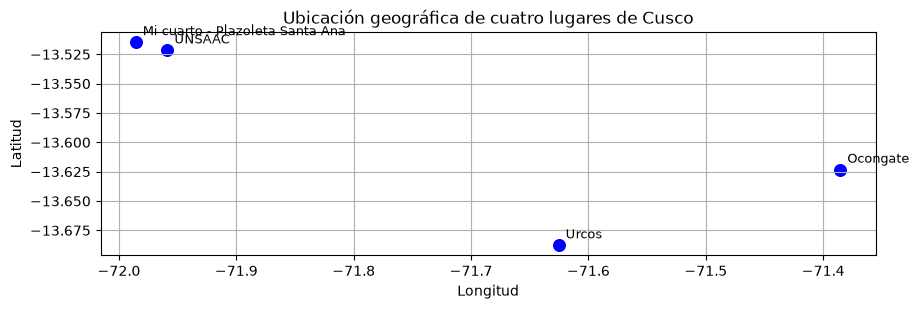

In [16]:
#Graficar los lugares con Matplotlib
import matplotlib.pyplot as plt

# Extraer latitudes y longitudes
lats = [coord[0] for coord in lugares.values()]
lons = [coord[1] for coord in lugares.values()]

# Crear la figura
fig, ax = plt.subplots(figsize=(10, 7))

# Graficar los puntos
ax.scatter(lons, lats, color="blue", s=70)

# Agregar etiquetas
for nombre, (lat, lon) in lugares.items():
    ax.annotate(
        nombre,
        (lon, lat),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

# Configurar los ejes y el título
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Ubicación geográfica de cuatro lugares de Cusco")

ax.grid(True)
ax.set_aspect("equal")

# Guardar imagen
plt.savefig(
    "mapa_basico.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [22]:
##TAREA2
import math

def distancia_haversine(lat1, lon1, lat2, lon2):

    # Radio medio de la Tierra en kilómetros
    R = 6371

    # Convertir grados a radianes
    lat1 = math.radians(lat1)
    lon1 = math.radians(lon1)

    lat2 = math.radians(lat2)
    lon2 = math.radians(lon2)

    # Diferencias de coordenadas
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    # Fórmula de Haversine
    a = (math.sin(dlat / 2)**2 +
         math.cos(lat1) * math.cos(lat2) *
         math.sin(dlon / 2)**2)

    c = 2 * math.asin(math.sqrt(a))

    # Distancia en kilómetros
    distancia = R * c

    return distancia

    # Comprobar la función con dos lugares
distancia = distancia_haversine(
    -13.514673, -71.985582,
    -13.521667, -71.958611
)

print("Distancia entre Santa Ana y UNSAAC:")
print(f"{distancia:.3f} km")



Distancia entre Santa Ana y UNSAAC:
3.018 km


In [23]:

# Obtener el primer lugar
primer_nombre = list(lugares.keys())[0]

lat1, lon1 = lugares[primer_nombre]

print("DISTANCIAS DESDE:", primer_nombre)
print("----------------------------------")

# Calcular distancias
for nombre, (lat2, lon2) in list(lugares.items())[1:]:

    distancia = distancia_haversine(
        lat1, lon1,
        lat2, lon2
    )

    print(f"Hasta {nombre}: {distancia:.3f} km")


DISTANCIAS DESDE: Mi cuarto - Plazoleta Santa Ana
----------------------------------
Hasta UNSAAC: 3.018 km
Hasta Urcos: 43.438 km
Hasta Ocongate: 66.003 km


In [24]:

from itertools import combinations

# Lista para almacenar los resultados
resultados = []

# Calcular todas las combinaciones
for (nombre1, coord1), (nombre2, coord2) in combinations(
    lugares.items(), 2
):

    distancia = distancia_haversine(
        coord1[0], coord1[1],
        coord2[0], coord2[1]
    )

    resultados.append((nombre1, nombre2, distancia))

# Identificar el par más cercano
mas_cercano = min(resultados, key=lambda x: x[2])

# Identificar el par más lejano
mas_lejano = max(resultados, key=lambda x: x[2])

# Mostrar todos los resultados
print("TODAS LAS DISTANCIAS")
for nombre1, nombre2, distancia in resultados:
    print(f"{nombre1} - {nombre2}: {distancia:.3f} km")

print("\nPAR MÁS CERCANO")
print(mas_cercano[0], "-", mas_cercano[1])
print(f"Distancia: {mas_cercano[2]:.3f} km")

print("\nPAR MÁS LEJANO")
print(mas_lejano[0], "-", mas_lejano[1])
print(f"Distancia: {mas_lejano[2]:.3f} km")


TODAS LAS DISTANCIAS
Mi cuarto - Plazoleta Santa Ana - UNSAAC: 3.018 km
Mi cuarto - Plazoleta Santa Ana - Urcos: 43.438 km
Mi cuarto - Plazoleta Santa Ana - Ocongate: 66.003 km
UNSAAC - Urcos: 40.484 km
UNSAAC - Ocongate: 62.994 km
Urcos - Ocongate: 26.904 km

PAR MÁS CERCANO
Mi cuarto - Plazoleta Santa Ana - UNSAAC
Distancia: 3.018 km

PAR MÁS LEJANO
Mi cuarto - Plazoleta Santa Ana - Ocongate
Distancia: 66.003 km


In [25]:
##TAREA3

import json

# Crear la lista de características
features = []

# Recorrer los lugares
for nombre, (lat, lon) in lugares.items():

    feature = {
        "type": "Feature",

        "properties": {
            "nombre": nombre
        },

        "geometry": {
            "type": "Point",
            "coordinates": [lon, lat]
        }
    }

    features.append(feature)

# Crear el GeoJSON completo
geojson_mio = {
    "type": "FeatureCollection",
    "features": features
}

# Guardar archivo GeoJSON
with open("mis_lugares.geojson", "w", encoding="utf-8") as archivo:

    json.dump(
        geojson_mio,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("Archivo mis_lugares.geojson guardado correctamente.")


Archivo mis_lugares.geojson guardado correctamente.


In [26]:

# Reabrir el archivo
with open("mis_lugares.geojson", "r", encoding="utf-8") as archivo:

    datos = json.load(archivo)

# Verificar cantidad de características
print("Número de lugares:", len(datos["features"]))

# Verificar primer lugar
primer_lugar = datos["features"][0]

print("Primer lugar:")
print(primer_lugar["properties"]["nombre"])

print("Coordenadas:")
print(primer_lugar["geometry"]["coordinates"])

# Verificar estructura
assert datos["type"] == "FeatureCollection"

assert len(datos["features"]) == 4

assert datos["features"][0]["geometry"]["coordinates"] == [
    lugares[list(lugares.keys())[0]][1],
    lugares[list(lugares.keys())[0]][0]
]

print("\nVerificación correcta del archivo GeoJSON.")


Número de lugares: 4
Primer lugar:
Mi cuarto - Plazoleta Santa Ana
Coordenadas:
[-71.985582, -13.514673]

Verificación correcta del archivo GeoJSON.
